In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../../code')
from utils import simulate_single_server_queue_from_times
from tqdm import tqdm

<div dir="rtl">

## בתורים נרצה לחשב 4 מדדים שמהם נגזר הכל:

### 1. התפלגות זמן המתנה - נסמן כ $W_q$
### 2. התפלגות זמן שהייה: נסמן כ$W$ כלומר זמן המתנה + זמן שירות
### 3. התפלגות אורך התור: נסמן כ$L_q$.
### 4. התפלגות מספר הצרכנים במערכת (תור + שירות) נסמן כ$L$

## סימולציה כאומד:

### זוכרים אי-שם בשנה ב שלמדתם סטטיסטיקה?

### לא זוכרים? אנחנו פה כדי לעורר זכרונות

## מהו אומד? 

### פונקציה של הנתונים שמשערכת ערך מסוים.



<div dir="rtl"> 

### בקורס הזה נתעסק רק עם אומדים חסרי הטיה. 

### נרצה להקטין את השונות כמה שיותר. בשביל להקטין את השונות נרצה להריץ את הסימולציה כמה שיותר

# בדיקת שונות של אומד:

## בשביל זה צריך לעשות את אותה סימולציה כמה פעמים ונראה מה היה הערך החזוי כל פעם וכמה הערכים משתנים אחד מהשני.

### כעת נתרגל חישוב וניתוח מדדים בתורים

## נתחיל עם התפלגות זמן המתנה

In [12]:
inter_arrival_times = np.random.gamma(2,1/2,25000)
inter_arrival_times.mean()

np.float64(0.9999336238761863)

In [13]:
service_times = np.random.exponential(1/1.25, 25000)
service_times.mean()

np.float64(0.7975724756442593)

In [14]:
waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times,
)

In [15]:
waiting_times.shape

(25000,)

<div dir="rtl"> 

### בואו נציג את ההתפלגות של זמני המתנה:

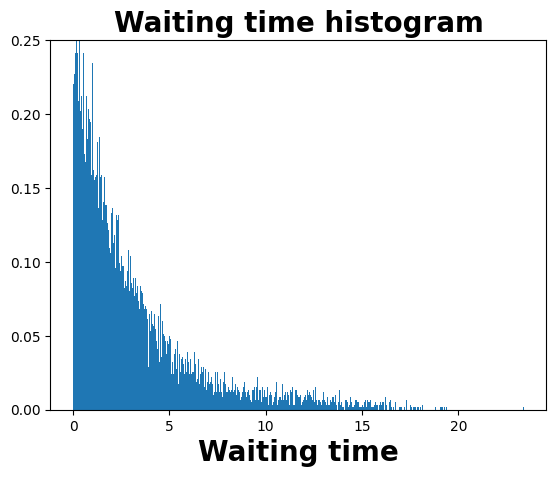

In [19]:
plt.figure()
plt.hist(waiting_times, density = True, bins = 1000)
plt.ylim(0,0.25)
plt.xlabel('Waiting time', fontsize = 20, fontweight = 'bold')
plt.title('Waiting time histogram', fontsize = 20, fontweight = 'bold')
plt.show()

<div dir="rtl"> 

### הסתברות שצרכן ימתין פחות מ-5 דקות?



In [25]:
(waiting_times<5).mean()

np.float64(0.85548)

<div dir="rtl"> 

### הסתברות שצרכן ימתין יותר מ-5 דקות?

In [21]:
(waiting_times>5).mean(), 1-(waiting_times<5).mean()

(np.float64(0.14452), np.float64(0.14451999999999998))

<div dir="rtl"> 

### מה ההסתברות שימתין בין 10 ל-12? 



In [23]:
((waiting_times>10)& (waiting_times<12)).mean()

np.float64(0.0184)

<div dir="rtl"> 

### בואו נציג את ההתפלגות של זמני שהייה:

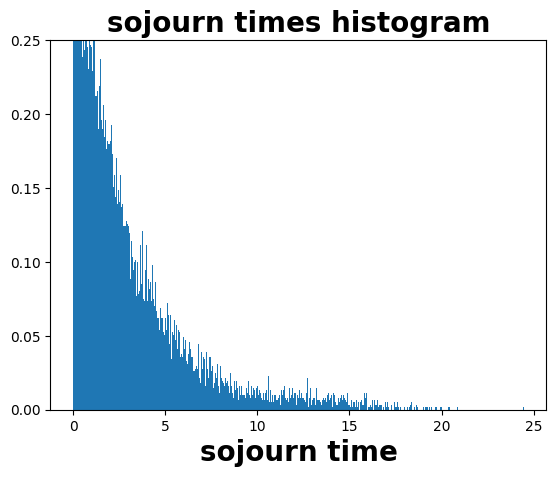

In [24]:
plt.figure()
plt.hist(sojourn_times, density = True, bins = 1000)
plt.ylim(0,0.25)
plt.xlabel('sojourn time', fontsize = 20, fontweight = 'bold')
plt.title('sojourn times histogram', fontsize = 20, fontweight = 'bold')
plt.show()

<div dir="rtl"> 

### בואו נציג את ההתפלגות של זמני שהייה יחד עם זמני המתנה

<>:6: SyntaxWarning: invalid escape sequence '\w'
<>:6: SyntaxWarning: invalid escape sequence '\w'
C:\Users\Eshel\AppData\Local\Temp\ipykernel_46528\263375115.py:6: SyntaxWarning: invalid escape sequence '\w'
  plt.title('sojourn\waiting times histogram', fontsize = 20, fontweight = 'bold')


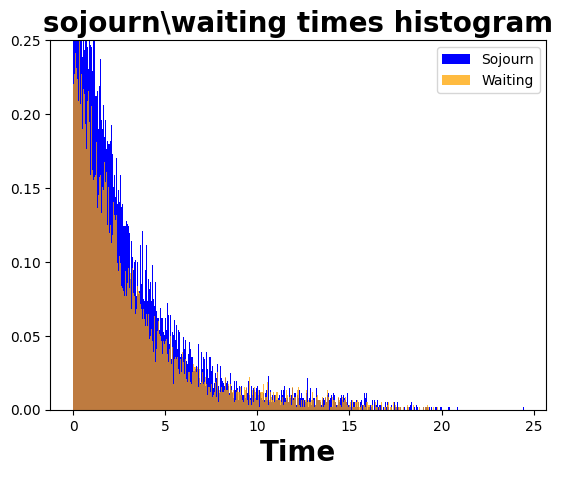

In [28]:
plt.figure()
plt.hist(sojourn_times, density = True, bins = 1000, color = 'blue', label = 'Sojourn')
plt.hist(waiting_times, density = True, bins = 1000, color = 'orange', label = 'Waiting', alpha = 0.75)
plt.ylim(0,0.25)
plt.xlabel('Time', fontsize = 20, fontweight = 'bold')
plt.title('sojourn\waiting times histogram', fontsize = 20, fontweight = 'bold')
plt.legend()
plt.show()

<div dir="rtl"> 

### ניתן לראות שזמני שהייה גדולים מזמני המתנה שזה כמובן נכון לפי הגדרה. 

### נא לחשב שונות זמן המתנה וזמן שהיה!

In [29]:
## Code here

<div dir="rtl"> 

### חישוב התפלגות אורך תור.

### כרגע הפלט נותן לנו ישירות את ההתפגלות במשתנה queue_length_distribution

### אם למשל נרצה את ההסתברות ל-5 צרכנים בתור אז פשוט נעשה:

In [31]:
queue_length_distribution[5]

np.float64(0.03992895833648577)

<div dir="rtl"> 

## ואם נרצה הסתברות שיהיו בתור בין 3 ל-7 צרכנים: 


In [34]:
queue_length_distribution[3:8].sum()

np.float64(0.22977135771733137)

<div dir="rtl"> 


### נא לחשב תוחלת אורך התור!


In [35]:
## your code here

<div dir="rtl"> 

### התפלגות מספר הצרכנים במערכת לא שונה מאופן החישוב של אורך התור - זו רק שאלה של מה שמעניין אותנו

### נניח כי המערכת רוצה שרוב הזמן יהיו בתור בין 1 ל-10 צרכנים במערכת. 

### מה צריך להיות קצב השירות כך שההסתברות שיהיו בין 1-ל10 תהיה מעל 0.75?

### השליטה שלנו בקצב השירות דרך הקוד הבא:

In [47]:
service_rate = 2

inter_arrival_times = np.random.gamma(2,1/2,25000)
service_times = np.random.exponential(1/service_rate, 25000)
service_times.mean()

np.float64(0.5034071995574089)

<div dir="rtl"> 

### כלומר מניחים פה שהתפלגות זמן ההמתנה מפולגת גאמה

### נבדוק כל מיני קבצי שירות מ0.51 עד 3. 

### נשים לב שקצב הגעה הוא 0.5 ונדרוש כי קצב שירות יהיה מהיר יותר

In [59]:
prob_1_10_list = []


for service_rate in np.linspace(0.51, 3, 50):
    inter_arrival_times = np.random.gamma(2,1/2,25000)
    service_times = np.random.exponential(1/service_rate, 25000)
    waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times,
)
    prob_1_10_list.append(queue_length_distribution[1:11].sum())

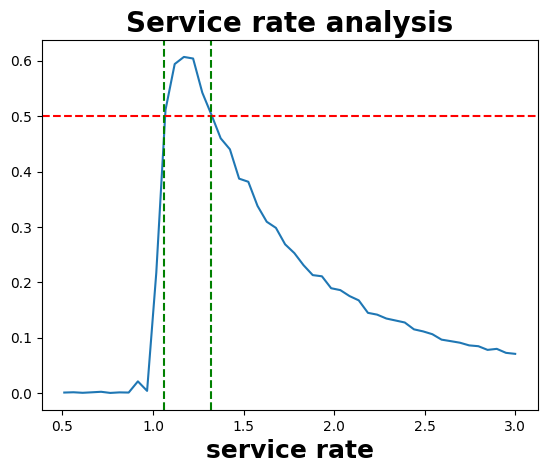

In [69]:
plt.figure()
plt.plot( np.linspace(0.51, 3, 50), prob_1_10_list)
plt.axhline(y=0.5, color='r', linestyle='--')
plt.axvline(x=1.06, color='g', linestyle='--')
plt.axvline(x=1.32, color='g', linestyle='--')

plt.xlabel('service rate', fontsize = 18, fontweight = 'bold')
plt.title('Service rate analysis', fontsize = 20, fontweight = 'bold')
plt.show()

<div dir="rtl"> 

## נראה שקצב השירות צריך להיות בין 1.06 ל1.32

###  שאלה למחשבה: למה רק הקצב משנה כאן? הרי כל ההתפלגות משפיע על אורך התור...